# Pre-requisite

In [46]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2

In [47]:
# Helper function to display images
def show_image(img, title='Image', cmap=None):
    plt.figure(figsize=(5, 5))
    plt.imshow(img, cmap=cmap)
    plt.title(title)
    plt.axis('off')
    plt.show()

### Load Image

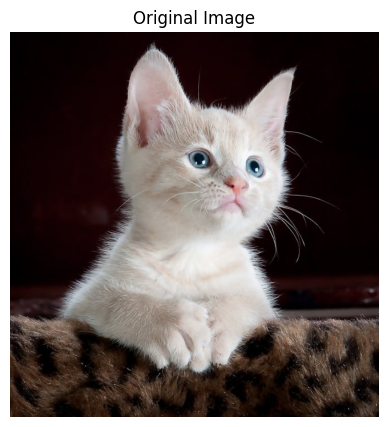

In [48]:
# Load image (OpenCV loads in BGR)
img = cv2.imread('kitty.jpeg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
show_image(img_rgb, 'Original Image')

# 1. Image Preprocessing

## 🧼 Image Preprocessing in Computer Vision

This section covers basic image preprocessing techniques to prepare images before training a machine learning model.

## 🔧 Techniques Covered
- Reading and visualizing images
- Resizing
- Cropping
- Color Space Conversion (BGR to RGB, Grayscale)
- Noise Reduction (Gaussian, Median, Bilateral)



### Resize

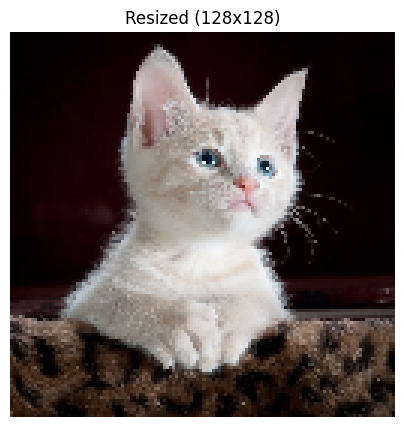

In [33]:
# Resize image
resized = cv2.resize(img_rgb, (128, 128))
show_image(resized, 'Resized (128x128)')

### Crop

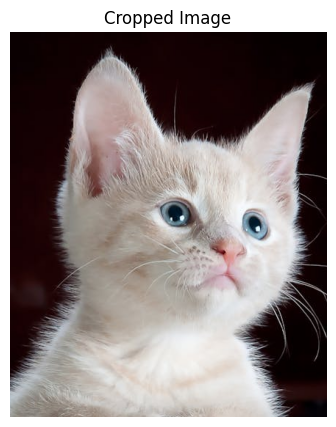

In [34]:
# Crop Image at the Center Top
h, w, _ = img_rgb.shape

crop_percent_horizontal = 0.20
crop_percent_vertical = 0.30

start_col = int(w * crop_percent_horizontal)
end_col = int(w * (1 - crop_percent_horizontal))
start_row = 0
end_row = int(h * (1 - crop_percent_vertical))

cropped_img = img_rgb[start_row:end_row, start_col:end_col]
show_image(cropped_img, 'Cropped Image')

### Color Space Conversion

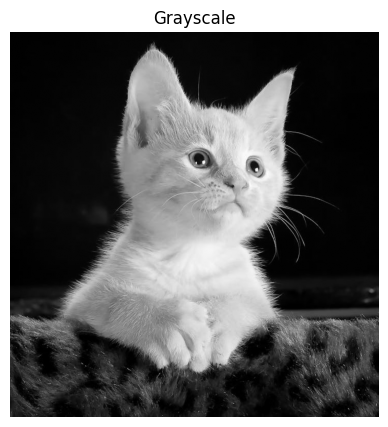

In [35]:
# Convert to Grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
show_image(gray, 'Grayscale', cmap='gray')

### Noise Reduction

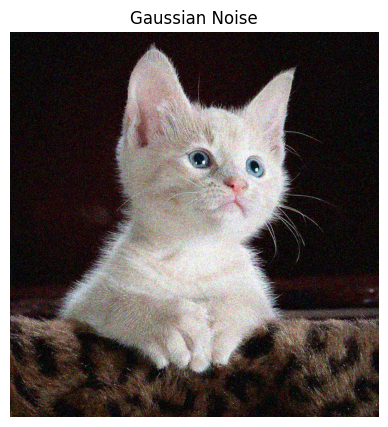

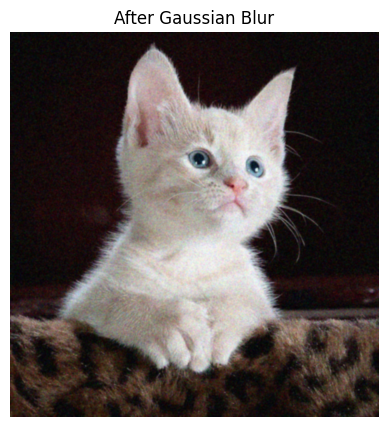

In [36]:
# Gaussian Noise + Gaussian Blur
def add_gaussian_noise(image, mean=0, std=25):
    noise = np.random.normal(mean, std, image.shape).astype(np.float32)
    noisy_img = np.clip(image.astype(np.float32) + noise, 0, 255).astype(np.uint8)
    return noisy_img

gaussian_noisy = add_gaussian_noise(img_rgb)
show_image(gaussian_noisy, 'Gaussian Noise')

# Apply Gaussian Blur
gaussian_denoised = cv2.GaussianBlur(gaussian_noisy, (5, 5), 0)
show_image(gaussian_denoised, 'After Gaussian Blur')

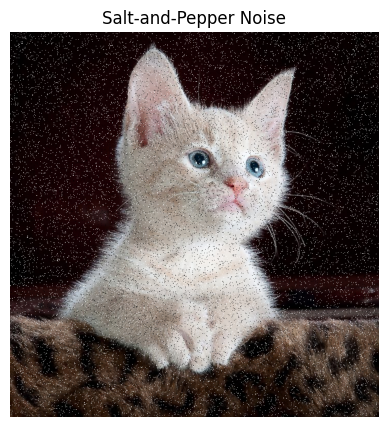

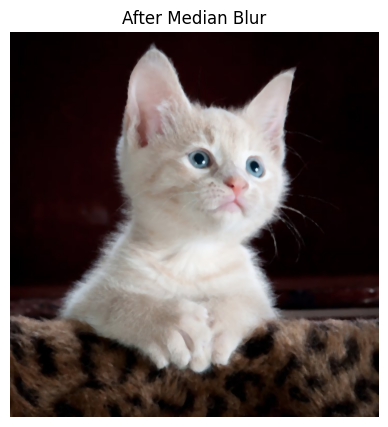

In [37]:
# Salt-and-Pepper Noise + Median Blur ###
def add_salt_pepper_noise(image, amount=0.02):
    noisy = image.copy()
    num_salt = np.ceil(amount * image.size * 0.5).astype(int)
    num_pepper = np.ceil(amount * image.size * 0.5).astype(int)

    # Salt (white) noise
    coords = [np.random.randint(0, i - 1, num_salt) for i in image.shape[:2]]
    noisy[coords[0], coords[1]] = [255, 255, 255]

    # Pepper (black) noise
    coords = [np.random.randint(0, i - 1, num_pepper) for i in image.shape[:2]]
    noisy[coords[0], coords[1]] = [0, 0, 0]

    return noisy

sp_noisy = add_salt_pepper_noise(img_rgb)
show_image(sp_noisy, 'Salt-and-Pepper Noise')

# Apply Median Blur
median_denoised = cv2.medianBlur(sp_noisy, 5)
show_image(median_denoised, 'After Median Blur')

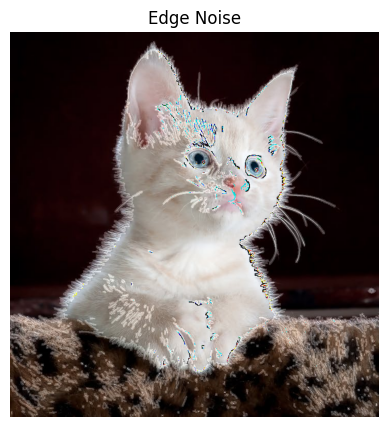

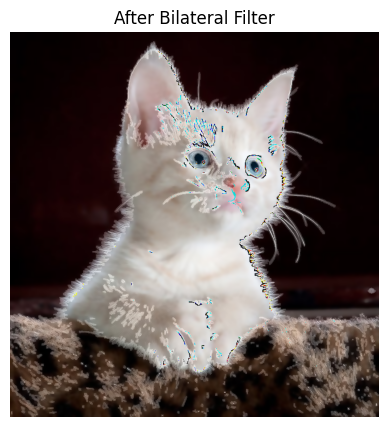

In [38]:
# Mixed Edge Noise + Bilateral Filter ###
def add_edge_noise(image):
    edge = cv2.Canny(cv2.cvtColor(image, cv2.COLOR_RGB2GRAY), 100, 200)
    edge = cv2.dilate(edge, None)
    noisy = image.copy()
    noisy[edge > 0] = np.clip(noisy[edge > 0] + 50, 0, 255)
    return noisy

edge_noisy = add_edge_noise(img_rgb)
show_image(edge_noisy, 'Edge Noise')

# Apply Bilateral Filter
bilateral_denoised = cv2.bilateralFilter(edge_noisy, d=9, sigmaColor=75, sigmaSpace=75)
show_image(bilateral_denoised, 'After Bilateral Filter')

# 2. Image Augmentation

## 🔁 Image Augmentation in Computer Vision

Image augmentation is used to artificially expand the size and variability of the training dataset.

## 🛠️ Techniques Covered
- Manual augmentation: flipping, rotation, brightness/contrast
- Using `Albumentations` for flexible pipelines


## Horizontal Flip

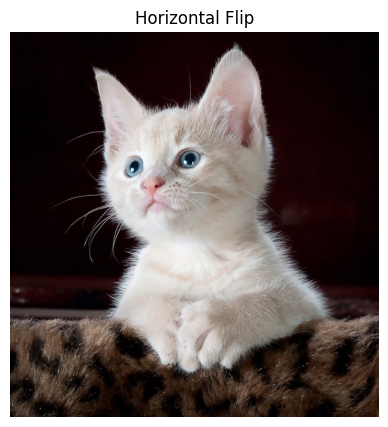

In [39]:
flip_h = cv2.flip(img_rgb, 1)
show_image(flip_h, 'Horizontal Flip')

## Rotation

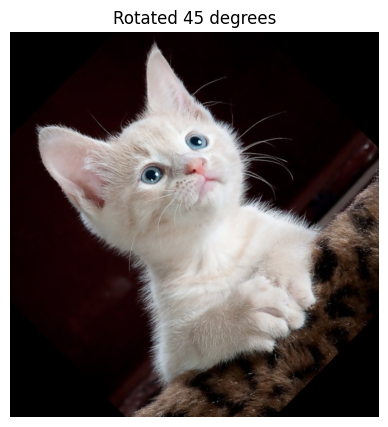

In [40]:
(h, w) = img_rgb.shape[:2]
center = (w // 2, h // 2)
M = cv2.getRotationMatrix2D(center, 45, 1.0)
rotated = cv2.warpAffine(img_rgb, M, (w, h))
show_image(rotated, 'Rotated 45 degrees')

## Brightness & Contrast

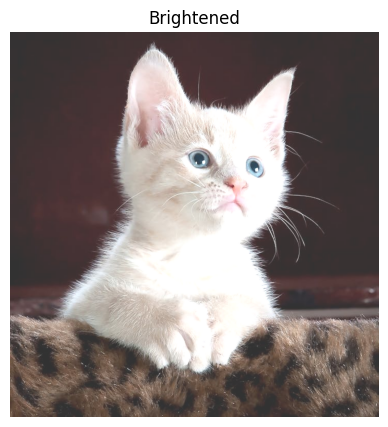

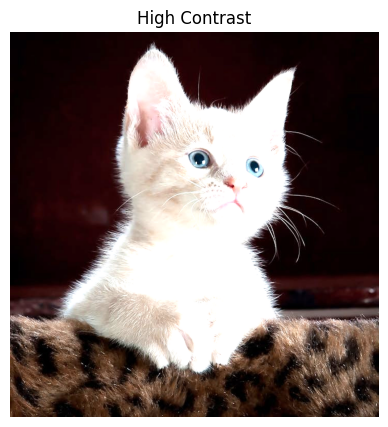

In [41]:
bright = cv2.convertScaleAbs(img_rgb, alpha=1.0, beta=50)
contrast = cv2.convertScaleAbs(img_rgb, alpha=1.5, beta=0)
show_image(bright, 'Brightened')
show_image(contrast, 'High Contrast')

## Using Albumentation

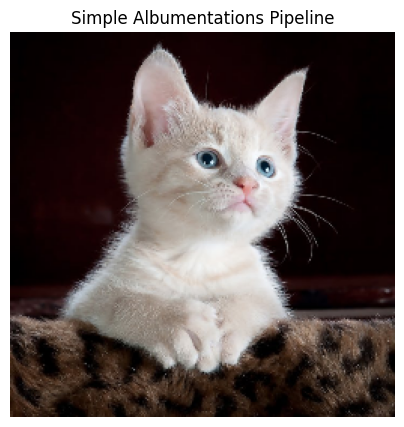

In [42]:
# Albumentations pipeline
transform_simple = A.Compose([
    A.Resize(width=256, height=256),
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=30, p=0.5),
    A.RandomBrightnessContrast(p=0.3),
])

# Apply augmentation and visualize
augmented_simple = transform_simple(image=img_rgb)['image']
show_image(augmented_simple, 'Simple Albumentations Pipeline')

# Quiz

## Quiz 1: Restore a Low-Quality Image

1. Download or load a poor-quality image (e.g., faded old photo, low-light, or blurred).
2. Improve its contrast (you choose the method).
3. Reduce the noise.
4. Resize it to a standard size (e.g. 256x256).
5. Display before and after side-by-side.


## Quiz 2: "Rotate to Fix Me!

1. Find and Load 3–5 test images that has random orientation.
2. Display all and identify their orientation.
3. Manually rotate them back to upright using code.
4. Visualize the before and after

## Quiz 3: Design Your Own Augmentation Strategy
1. Find and load 3 sample animal images.
2. Design a custom Albumentations pipeline, must include at least 5 steps.
3. Visualize the augmented images side-by-side with original.

## Quiz 4: Conditional Augmentation (Advanced Logic)
1. Write a function that:
   - Checks average brightness of an image.
   - If bright: apply `Noise Reduction`.
   - If dark: apply `Rotate` or `HorizontalFlip`.
2. Test it on a batch of images.

In [50]:
treshold =  #sets your own treshold
brightness = np.mean(img_rgb)

if brightness < treshold:
    print("Image is dark")
else:
    print("Image is bright")

Image is dark
